In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy import stats

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.2f}".format)

print("Libraries Loaded")

Libraries Loaded


In [42]:
df01 = pd.read_csv(r"file:///C:/Users/rajni/Downloads/bikes.csv")

print("dataset shape", df01.shape)

dataset shape (7857, 8)


In [43]:
print(df01['owner'].unique())
print("\n",df01['owner'].value_counts())
print("\n", df01.dtypes)
print("\nDuplicated values:", df01.duplicated().sum())
print("\nNull values:","\n", df01.isnull())

<StringArray>
['first owner', 'third owner', 'second owner', 'fourth owner or more']
Length: 4, dtype: str

 owner
first owner             6817
second owner             833
third owner              134
fourth owner or more      73
Name: count, dtype: int64

 model_name      str
model_year    int64
kms_driven      str
owner           str
location        str
mileage         str
power           str
price         int64
dtype: object

Duplicated values: 0

Null values: 
       model_name  model_year  kms_driven  owner  location  mileage  power  \
0          False       False       False  False     False    False  False   
1          False       False       False  False     False    False  False   
2          False       False       False  False     False    False  False   
3          False       False       False  False     False    False  False   
4          False       False       False  False     False    False  False   
...          ...         ...         ...    ...       ...      ... 

In [44]:
df01['price'].describe()

count      7857.00
mean     106791.34
std      138926.12
min           0.00
25%       42000.00
50%       75000.00
75%      125000.00
max     3000000.00
Name: price, dtype: float64

In [45]:
df01[['kms_driven','mileage','power']]

,kms_driven,mileage,power
0,17000 Km,\n\n 35 kmpl,19 bhp
1,50000 Km,\n\n 35 kmpl,19.80 bhp
2,14795 Km,\n\n 30 kmpl,28 bhp
3,Mileage 28 Kms,\n\n 28 Kms,34.50 bhp
4,2000 Km,\n\n,30 bhp
...,...,...,...
7852,7000 Km,\n\n 42 kmpl,16 bhp
7853,Mileage 80 Kmpl,\n\n 80 Kmpl,7.7
7854,6407 Km,\n\n 65 kmpl,17 bhp
7855,7524 Km,\n\n 57 kmpl,11.80 bhp


In [46]:
def get_number(value):
    if pd.isna(value):
        return np.nan
    value = str(value).replace(',','')
    number=''
    dot_used = False

    for i in value:
        if i.isdigit():
            number+=i
        elif i=='.' and not dot_used:
            dot_used = True
        elif number:
            break
    return float(number) if number else np.nan

In [47]:
column_name = ['mileage','kms_driven', 'power', 'price', 'model_year']
for i in column_name:
    df01[i] = df01[i].apply(get_number)

df01

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017.00,17000.00,first owner,hyderabad,35.00,19.00,63500.00
1,Royal Enfield Classic 350cc 2016,2016.00,50000.00,first owner,hyderabad,35.00,1980.00,115000.00
2,Hyosung GT250R 2012,2012.00,14795.00,first owner,hyderabad,30.00,28.00,300000.00
3,Bajaj Dominar 400 ABS 2017,2017.00,28.00,first owner,pondicherry,28.00,3450.00,100000.00
4,Jawa Perak 330cc 2020,2020.00,2000.00,first owner,bangalore,NaN,30.00,197500.00
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011.00,7000.00,first owner,agra,42.00,16.00,55000.00
7853,Bajaj Discover 100cc 2015,2015.00,80.00,first owner,delhi,80.00,77.00,28000.00
7854,Bajaj Pulsar 180cc 2016,2016.00,6407.00,first owner,bangalore,65.00,17.00,61740.00
7855,Bajaj V15 150cc 2016,2016.00,7524.00,first owner,bangalore,57.00,1180.00,49000.00


In [48]:
df01.dropna(subset='price')
df=df01[df01['price']>0]
df

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017.00,17000.00,first owner,hyderabad,35.00,19.00,63500.00
1,Royal Enfield Classic 350cc 2016,2016.00,50000.00,first owner,hyderabad,35.00,1980.00,115000.00
2,Hyosung GT250R 2012,2012.00,14795.00,first owner,hyderabad,30.00,28.00,300000.00
3,Bajaj Dominar 400 ABS 2017,2017.00,28.00,first owner,pondicherry,28.00,3450.00,100000.00
4,Jawa Perak 330cc 2020,2020.00,2000.00,first owner,bangalore,NaN,30.00,197500.00
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011.00,7000.00,first owner,agra,42.00,16.00,55000.00
7853,Bajaj Discover 100cc 2015,2015.00,80.00,first owner,delhi,80.00,77.00,28000.00
7854,Bajaj Pulsar 180cc 2016,2016.00,6407.00,first owner,bangalore,65.00,17.00,61740.00
7855,Bajaj V15 150cc 2016,2016.00,7524.00,first owner,bangalore,57.00,1180.00,49000.00


In [49]:
if 'model_year' in df.columns:
    current_year = pd.Timestamp.today().year
    df['model_year']=df['model_year'].between(1998, current_year)

In [50]:
if 'model_year' in df.columns:
    current_year = pd.Timestamp.today().year
    df['bike_age'] = current_year - df['model_year']

In [51]:
for col in['kms_driven', 'mileage', 'power']:
    if col in df.columns:
        df.loc[df[col]<0, col] = np.nan

In [52]:
dfc = df.copy()
dfc.to_csv('bikes_cleaned.csv', index = False)


display(dfc)

,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age
0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500.00,2025
1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,1980.00,115000.00,2025
2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000.00,2025
3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,3450.00,100000.00,2025
4,Jawa Perak 330cc 2020,True,2000.00,first owner,bangalore,NaN,30.00,197500.00,2025
...,...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,True,7000.00,first owner,agra,42.00,16.00,55000.00,2025
7853,Bajaj Discover 100cc 2015,True,80.00,first owner,delhi,80.00,77.00,28000.00,2025
7854,Bajaj Pulsar 180cc 2016,True,6407.00,first owner,bangalore,65.00,17.00,61740.00,2025
7855,Bajaj V15 150cc 2016,True,7524.00,first owner,bangalore,57.00,1180.00,49000.00,2025


CLEANED DATASET

In [53]:
dfc['price'].describe()

count      7826.00
mean     107214.35
std      139038.02
min        2000.00
25%       42500.00
50%       75000.00
75%      125000.00
max     3000000.00
Name: price, dtype: float64

In [54]:
dfc['price'].skew()

np.float64(6.214268795526774)

<Axes: xlabel='price', ylabel='Count'>

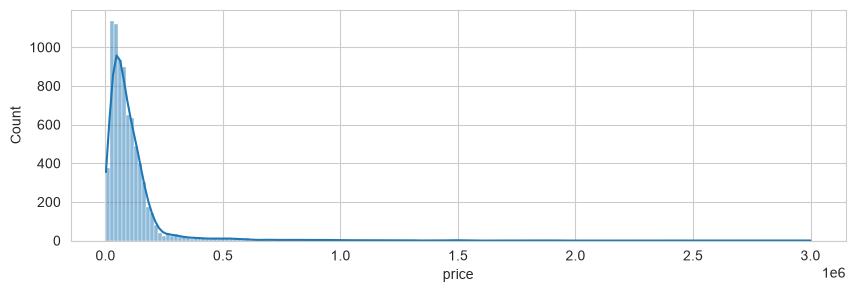

In [55]:
plt.figure(figsize=(10,3))
sns.histplot(data = dfc, x='price', kde=True)

<Axes: xlabel='price'>

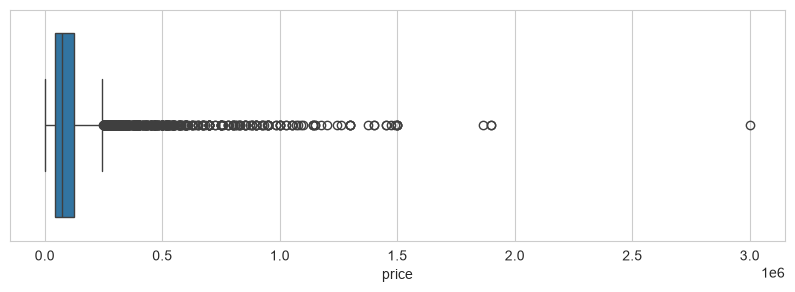

In [56]:
plt.figure(figsize=(10,3))
sns.boxplot(data = dfc, x='price')

In [57]:
dfc['brand_name']=dfc['model_name'].str.split().str[0].str.lower()
dfc['brand_name'].unique()

array(['bajaj', 'royal', 'hyosung', 'jawa', 'ktm', 'tvs', 'yamaha',
       'honda', 'um', 'hero', 'suzuki', 'husqvarna', 'mahindra',
       'harley-davidson', 'kawasaki', 'benelli', 'triumph', 'ducati',
       'bmw', 'ideal', 'benelliimperiale', 'moto', 'fb', 'indian',
       'yazdi', 'aprilia', 'mv'], dtype=object)

In [58]:
brand_stats = dfc.groupby('brand_name')['price'].agg(['median','mean','count']).reset_index()
brand_top_10= brand_stats[brand_stats['count']>10].sort_values(by='median', ascending=False).head(10)
brand_top_10

,brand_name,median,mean,count
5,ducati,907293.50,976293.69,16
22,triumph,800000.00,843183.25,36
15,kawasaki,465000.00,496517.70,67
7,harley-davidson,450000.00,512722.60,171
2,benelli,260000.00,301581.89,53
10,husqvarna,205000.00,206767.00,11
11,hyosung,198600.00,221660.19,52
14,jawa,165000.00,171286.13,46
16,ktm,147000.00,150354.56,491
24,um,125000.00,128446.01,128


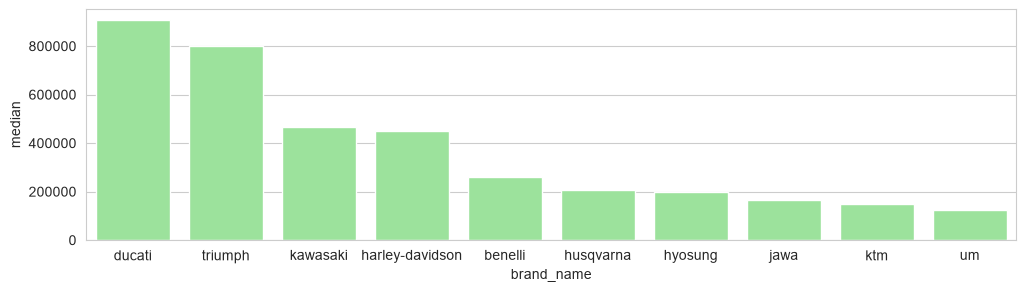

In [59]:
plt.figure(figsize=(12,3))
sns.barplot(data = brand_top_10, x = 'brand_name', y='median', color='lightgreen')
plt.show()

In [60]:
dfc[['kms_driven','price']].corr()

,kms_driven,price
kms_driven,1.00,-0.11
price,-0.11,1.00


<Axes: xlabel='kms_driven', ylabel='price'>

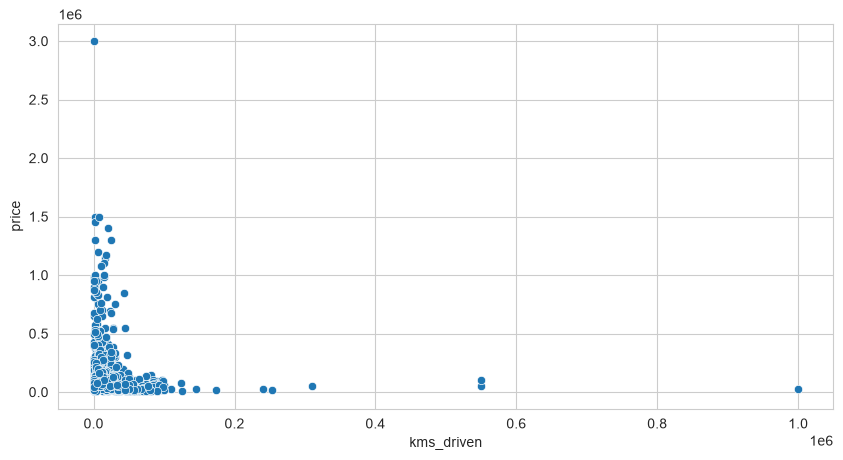

In [61]:
plot_data = dfc.dropna(subset=['kms_driven','price'])
if len(plot_data)>1000:
    plot_data = plot_data.sample(3000, random_state=42)

plt.figure(figsize=(10,5))
sns.scatterplot(data=plot_data,x='kms_driven',y='price')

<Axes: xlabel='kms_driven', ylabel='price'>

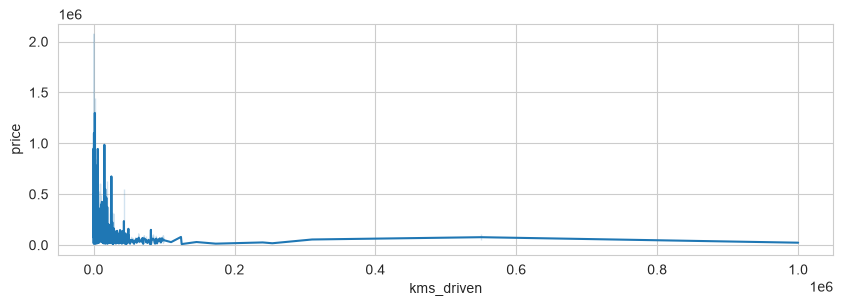

In [62]:
plt.figure(figsize=(10,3))
sns.lineplot(data=plot_data,x='kms_driven',y='price')

<Axes: xlabel='bike_age', ylabel='price'>

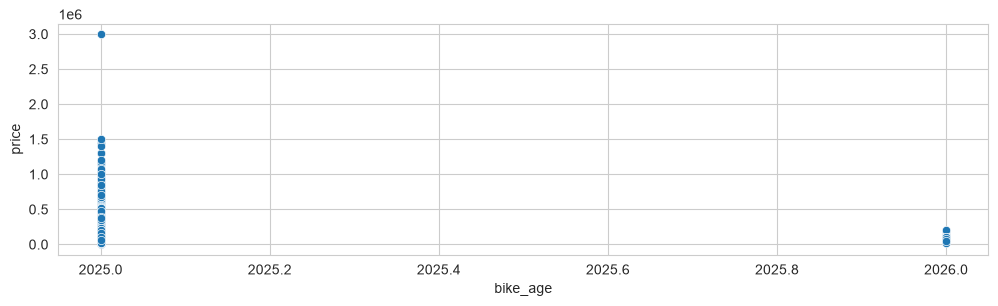

In [63]:
plot_data = dfc.dropna(subset=['bike_age','price'])
if len(plot_data)>1000:
    plot_data = plot_data.sample(3000, random_state=42)

plt.figure(figsize=(12,3))
sns.scatterplot(data=plot_data,x='bike_age',y='price')

<Axes: >

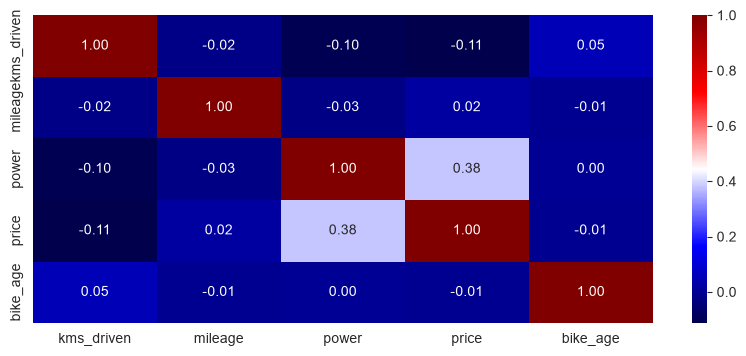

In [64]:
numeric_dfc = dfc.select_dtypes(include='number')
plt.figure(figsize=(10,4))
sns.heatmap(data = numeric_dfc.corr(),cmap='seismic', annot=True, fmt='.2f')

In [65]:
dfc.dropna(inplace=True)
dfc.reset_index(inplace=True,drop='first')
dfc

,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age,brand_name
0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500.00,2025,bajaj
1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,1980.00,115000.00,2025,royal
2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000.00,2025,hyosung
3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,3450.00,100000.00,2025,bajaj
4,KTM Duke 200cc 2012,True,24561.00,third owner,bangalore,35.00,25.00,63400.00,2025,ktm
...,...,...,...,...,...,...,...,...,...,...
7025,Yamaha YZF-R15 150cc 2011,True,7000.00,first owner,agra,42.00,16.00,55000.00,2025,yamaha
7026,Bajaj Discover 100cc 2015,True,80.00,first owner,delhi,80.00,77.00,28000.00,2025,bajaj
7027,Bajaj Pulsar 180cc 2016,True,6407.00,first owner,bangalore,65.00,17.00,61740.00,2025,bajaj
7028,Bajaj V15 150cc 2016,True,7524.00,first owner,bangalore,57.00,1180.00,49000.00,2025,bajaj


create a regression model, drop (model name, location)

In [66]:
dfc02 = dfc.drop(['model_name','location'],axis=1)

In [67]:
x = dfc02[['model_year', 'kms_driven', 'owner', 'mileage', 'power', 'bike_age', 'brand_name']]
y = dfc02['price']

In [80]:

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test= train_test_split(x,y, random_state=42, test_size=0.2)

numerical_columns = x.select_dtypes(include = 'number').columns.tolist()
categorical_columns = x.select_dtypes(exclude = 'number').columns.tolist()


In [78]:
numeric_pipeline = Pipeline(steps=[('imputer', SimpleImputer(strategy='median'))])
categorical_pipeline = Pipeline(steps = [('imputer', SimpleImputer(strategy='most_frequent')),
('ohe',OneHotEncoder(handle_unknown='ignore'))])

In [79]:
transformers = []

if numerical_columns:
    transformers.append(
        ("numeric", numeric_pipeline, numerical_columns) )

if categorical_columns:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_columns))

preprocessor = ColumnTransformer(transformers=transformers)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

model.fit(x_train, y_train)

print("Linear Regression model trained")

Linear Regression model trained


In [83]:
y_pred = model.predict(x_test)

comparison = pd.DataFrame({
"actual price": y_test.values,
"predicted price": np.round(y_pred,0),
"error actual minus predicted": np.round(y_test.values - y_pred,0)
})

comparison["absolute error"] = comparison["error actual minus predicted"].abs()

display(comparison.head(5))

,actual price,predicted price,error actual minus predicted,absolute error
0,36000.00,52933.00,-16933.00,16933.00
1,45000.00,42524.00,2476.00,2476.00
2,75000.00,94919.00,-19919.00,19919.00
3,510000.00,575579.00,-65579.00,65579.00
4,130000.00,125135.00,4865.00,4865.00


In [84]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE: ₹{:,.0f}".format(mae))
print("MSE:  {:,.0f}".format(mse))
print("RMSE: ₹{:,.0f}".format(rmse))
print("R²: {:,.3f}".format(r2))


MAE: ₹39,506
MSE:  5,393,494,716
RMSE: ₹73,440
R²: 0.615


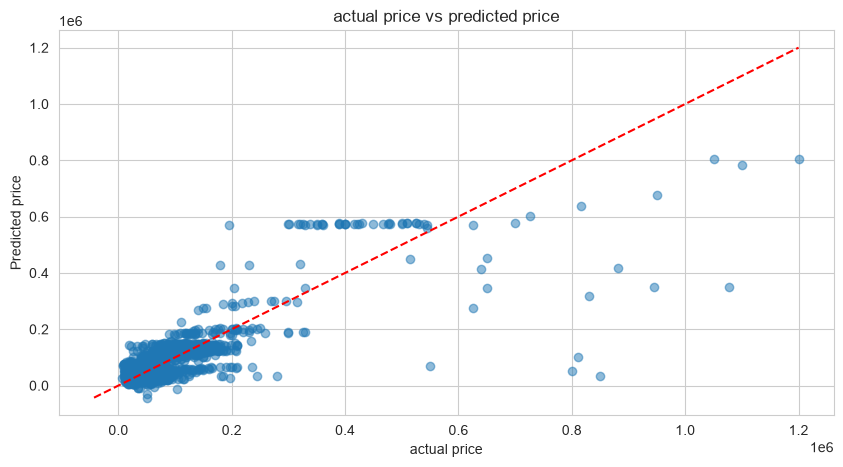

In [87]:
plt.figure(figsize=(10,5))
plt.scatter(y_test, y_pred, alpha = 0.5)
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value],[min_value, max_value], "r--")
plt.xlabel("actual price")
plt.ylabel("Predicted price")
plt.title("actual price vs predicted price")
plt.show()

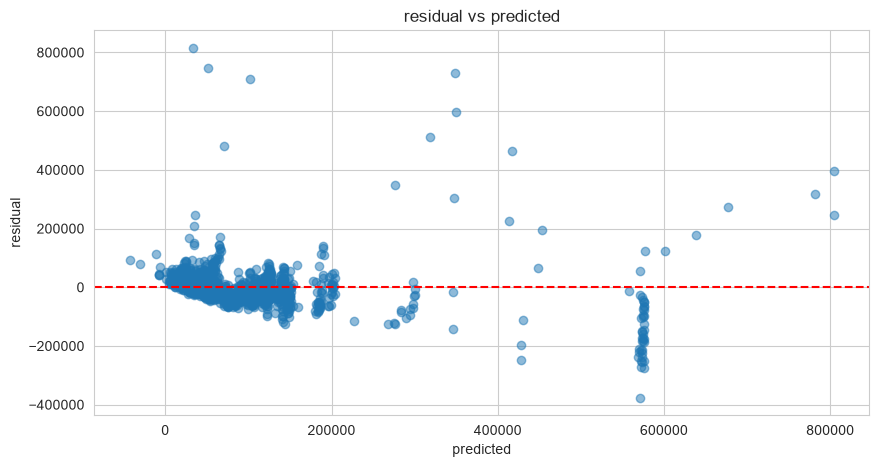

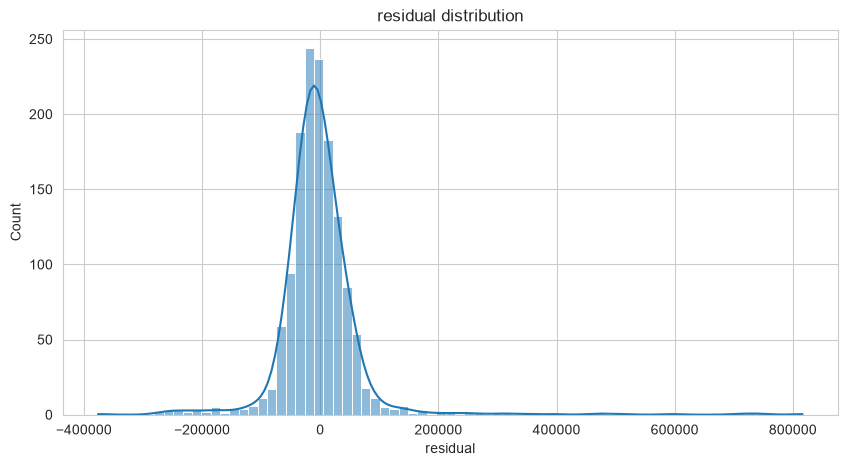

In [90]:
residuals = y_test - y_pred

plt.figure(figsize=(10,5))
plt.scatter(y_pred, residuals, alpha = 0.5)
plt.axhline(0, color = 'r', linestyle='--')
plt.xlabel("predicted")
plt.ylabel("residual")
plt.title("residual vs predicted")

plt.figure(figsize=(10,5))
sns.histplot(residuals, kde = True)
plt.title("residual distribution")
plt.xlabel("residual")
plt.show()
